# Echocardiography PCA

## Imports

In [43]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.decomposition import PCA
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF

## Resources location

**Note**: update **DINOV3_DIR** and **WEIGHTS_PATH** below 

In [51]:
DINOV3_DIR = Path('') # for example: /path/to/EchoDino_
WEIGHTS_PATH = Path('') # for example: /path/to/model.pth

IMAGE_DIR = Path('./resources/PCA_input')
IMAGE_PATTERN = '*.png'
OUTPUT_DIR = Path('./resources/PCA_output')

In [ ]:
if not DINOV3_DIR or str(DINOV3_DIR).strip() == ".":
    raise ValueError("Please specify the path for 'DINOV3_DIR'")

if not WEIGHTS_PATH or str(WEIGHTS_PATH).strip() == ".":
    raise ValueError("Please specify the path for 'WEIGHTS_PATH'")

## Hyperparameters

In [45]:
MODEL_NAME = 'dinov3_vitl16'
DEVICE = 'cuda'
IMAGE_SIZE = 256  # Image height before patch-size rounding.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

PCA_COMPONENTS = [9]#list(range(3, 15))
PCA_WHITEN = True
PCA_COLOR_SCALE = 2.0
PCA_RANDOM_STATE = 0
OVERLAY_ALPHA = 0.9
FIGURE_SIZE = (15, 5)
SAVE_DPI = 150

## Helper functions

In [46]:
def image_sort_key(path):
    return [
        int(part) if part.isdigit() else part.lower()
        for part in re.split(r'(\d+)', path.name)
    ]


def resize_transform(image, image_size, patch_size):
    width, height = image.size
    height_patches = max(1, image_size // patch_size)
    width_patches = max(1, int(width * image_size / (height * patch_size)))
    resized = TF.resize(
        image, (height_patches * patch_size, width_patches * patch_size),
    )
    return TF.to_tensor(resized)


@torch.inference_mode()
def extract_features(model, normalized_image, device):
    features = model.get_intermediate_layers(
        normalized_image.unsqueeze(0).to(device),
        n=1, reshape=True, norm=True,
    )[0]
    return features.squeeze(0).float().cpu()


def project_pca(features, n_components, whiten, color_scale, random_state):
    channels, height, width = features.shape
    patches = features.flatten(1).T.numpy()
    if n_components > min(patches.shape):
        raise ValueError(
            f'{n_components} components exceed the feature dimensions: {patches.shape}'
        )
    pca = PCA(
        n_components=n_components, whiten=whiten, random_state=random_state,
    )
    pca.fit(patches)
    projected = pca.transform(patches).reshape(height, width, n_components)
    rgb = torch.from_numpy(projected[..., -3:]).permute(2, 0, 1)
    return torch.sigmoid(rgb * color_scale)


def show_pca(image, resized_image, pca_rgb, image_name, n_components, output_path):
    overlay_rgb = F.interpolate(
        pca_rgb.unsqueeze(0), size=resized_image.shape[-2:],
        mode='bilinear', align_corners=False,
    ).squeeze(0).permute(1, 2, 0).numpy()

    fig, axes = plt.subplots(1, 3, figsize=FIGURE_SIZE)
    axes[0].imshow(image)
    axes[0].set_title('Input')
    axes[1].imshow(pca_rgb.permute(1, 2, 0).numpy())
    axes[1].set_title('PCA')
    axes[2].imshow(resized_image.permute(1, 2, 0).numpy())
    axes[2].imshow(overlay_rgb, alpha=OVERLAY_ALPHA)
    axes[2].set_title('Overlay')
    for ax in axes:
        ax.axis('off')
    fig.suptitle(f'{image_name} | Components: {n_components} | Last 3')
    fig.tight_layout()
    fig.savefig(output_path, dpi=SAVE_DPI, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## Model loading

In [47]:
if not (DINOV3_DIR / 'hubconf.py').is_file():
    raise FileNotFoundError(DINOV3_DIR / 'hubconf.py')
if not WEIGHTS_PATH.is_file():
    raise FileNotFoundError(WEIGHTS_PATH)

device = torch.device(DEVICE)
if device.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable.')

model = torch.hub.load(
    str(DINOV3_DIR), MODEL_NAME, source='local', pretrained=False,
)
checkpoint = torch.load(WEIGHTS_PATH, map_location='cpu', weights_only=True)
state_dict = {
    key.removeprefix('backbone.'): value
    for key, value in checkpoint['teacher'].items()
    if 'head' not in key
}
model.load_state_dict(state_dict, strict=True)
del checkpoint, state_dict
model = model.to(device).eval()
patch_size = model.patch_size
print(f'Model: {MODEL_NAME} | Device: {device}')

Model: dinov3_vitl16 | Device: cuda


## Data loading

In [48]:
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(IMAGE_DIR)
image_paths = sorted(IMAGE_DIR.glob(IMAGE_PATTERN), key=image_sort_key)
if not image_paths:
    raise FileNotFoundError(f'Images missing: {IMAGE_DIR / IMAGE_PATTERN}')
if not isinstance(IMAGE_SIZE, int) or IMAGE_SIZE <= 0:
    raise ValueError('IMAGE_SIZE must be a positive integer.')
if not PCA_COMPONENTS or any(
    not isinstance(count, int) or count < 3 for count in PCA_COMPONENTS
):
    raise ValueError('PCA_COMPONENTS must contain integers of at least 3.')
if not 0 <= OVERLAY_ALPHA <= 1:
    raise ValueError('OVERLAY_ALPHA must be in [0, 1].')
print(f'Images: {len(image_paths)}')

Images: 9


## PCA

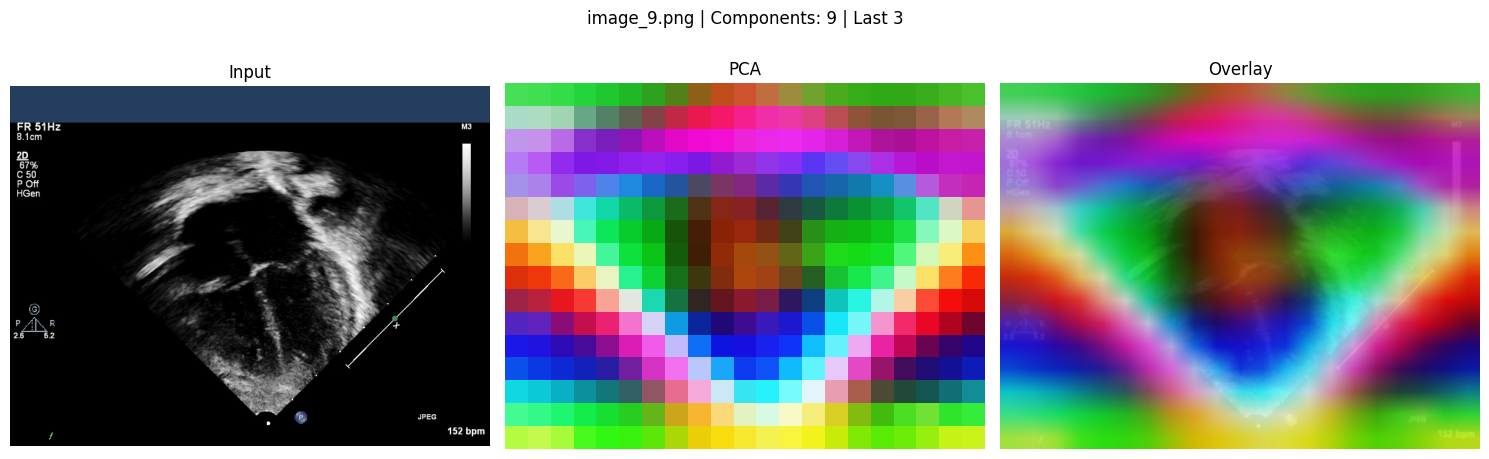

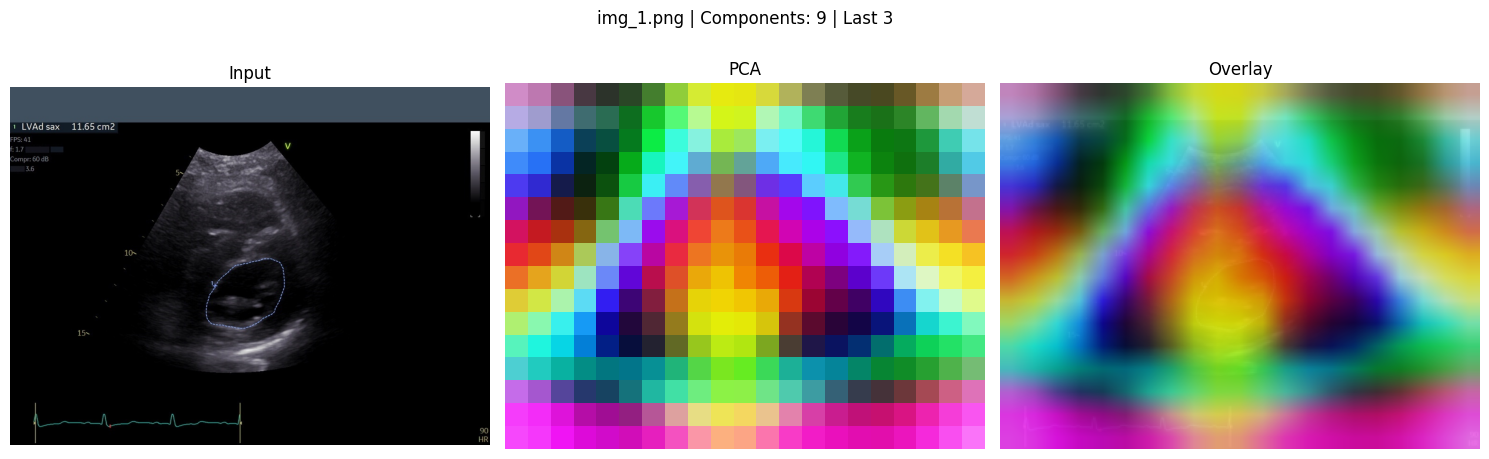

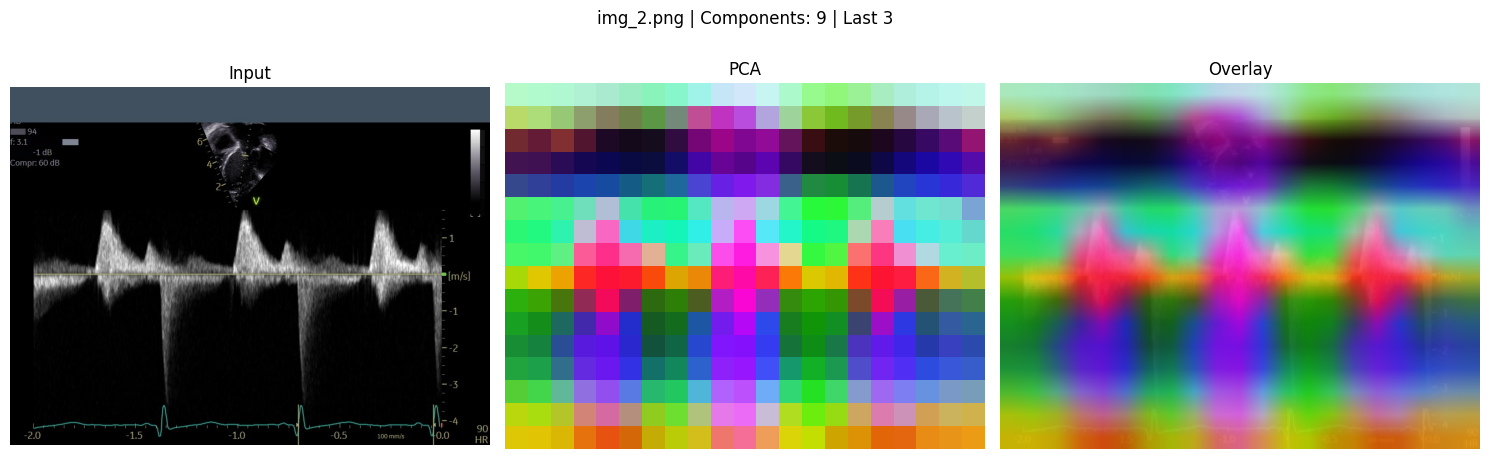

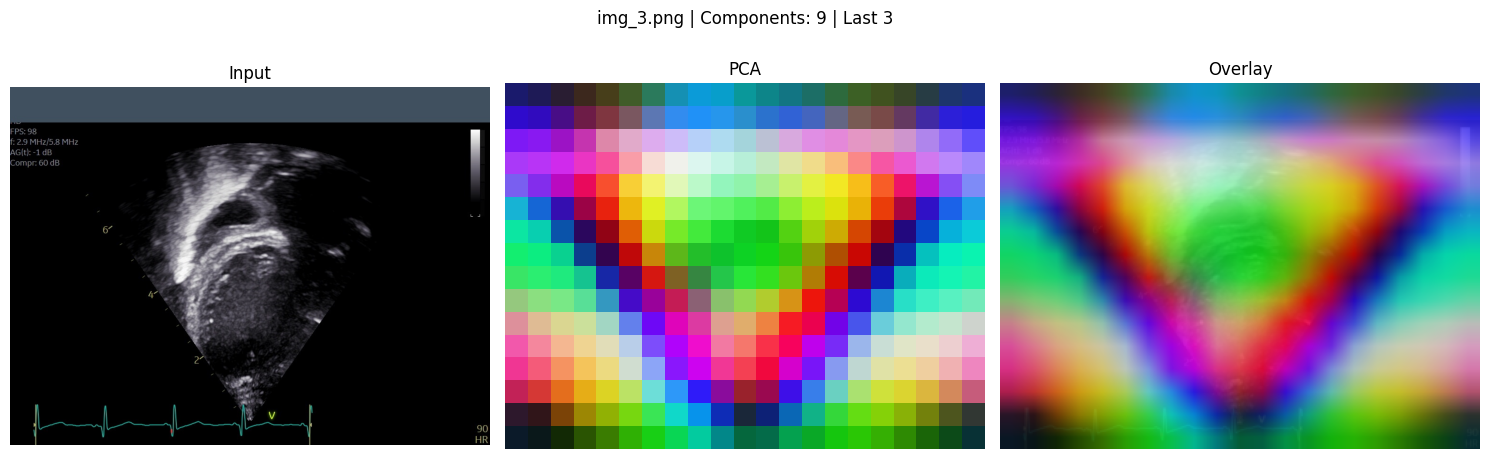

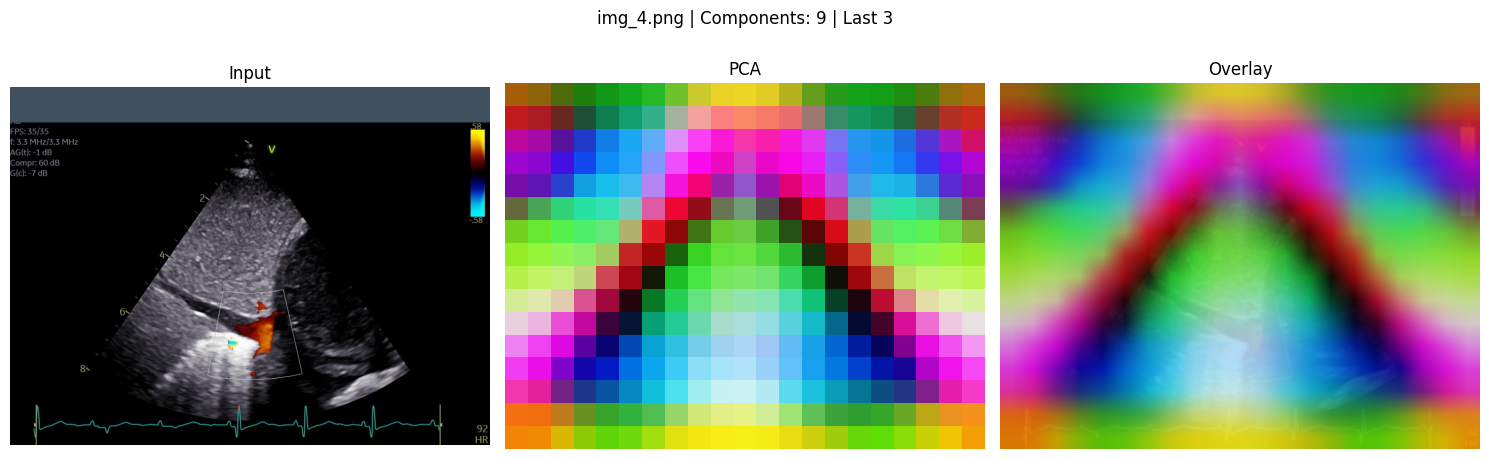

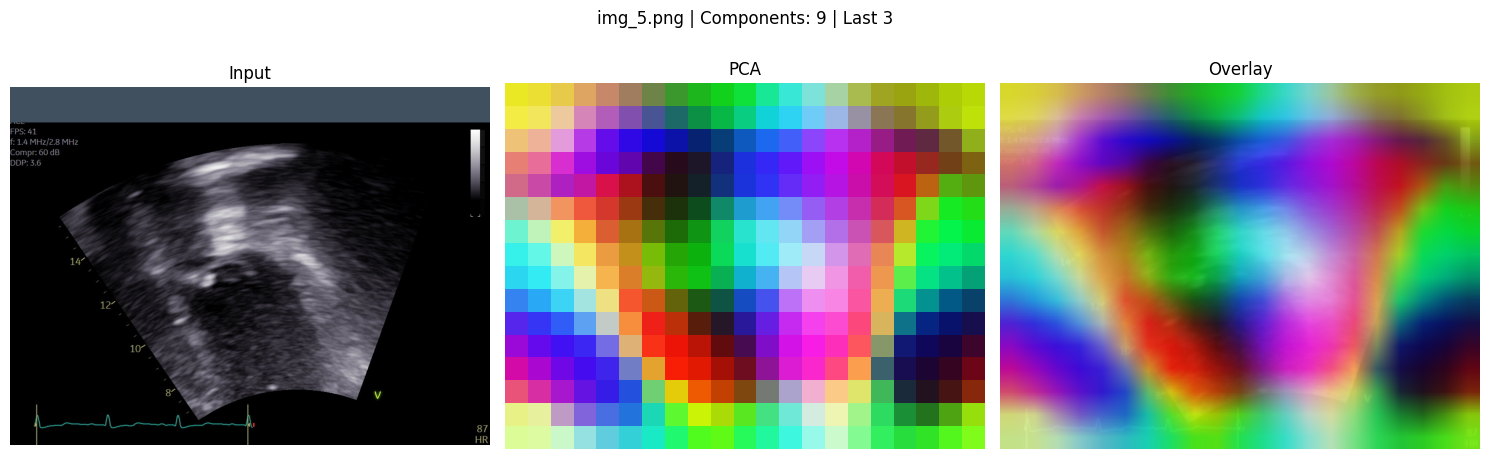

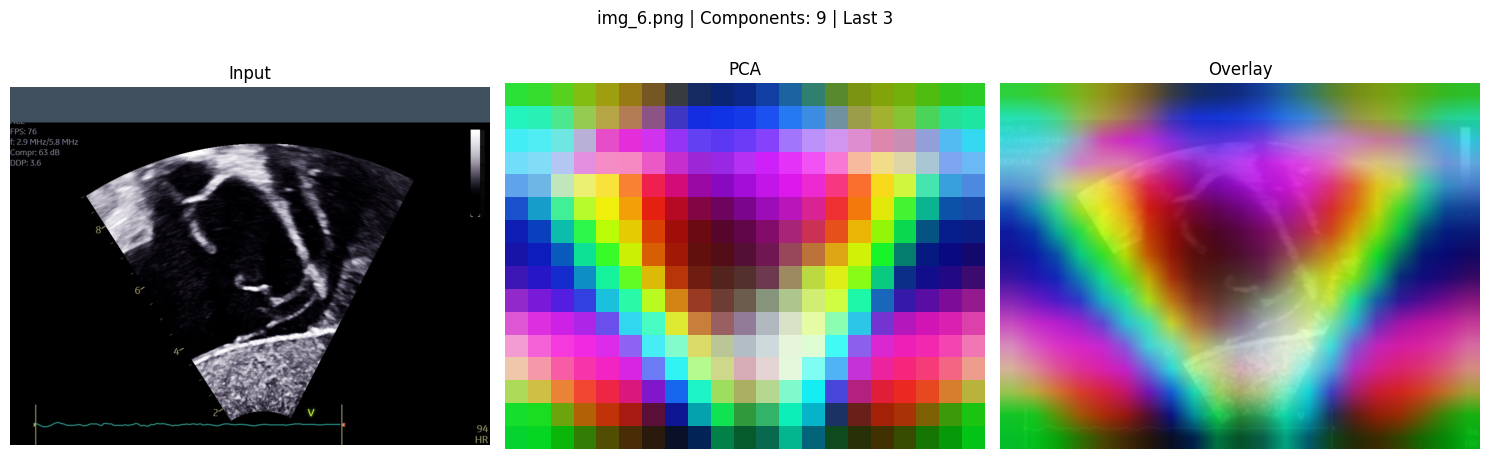

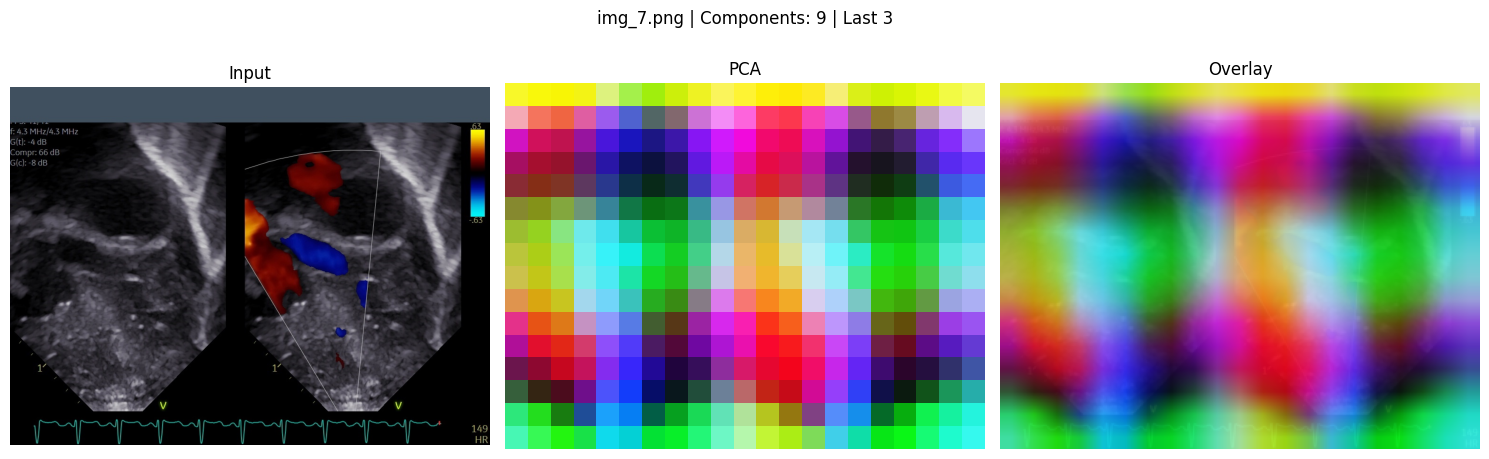

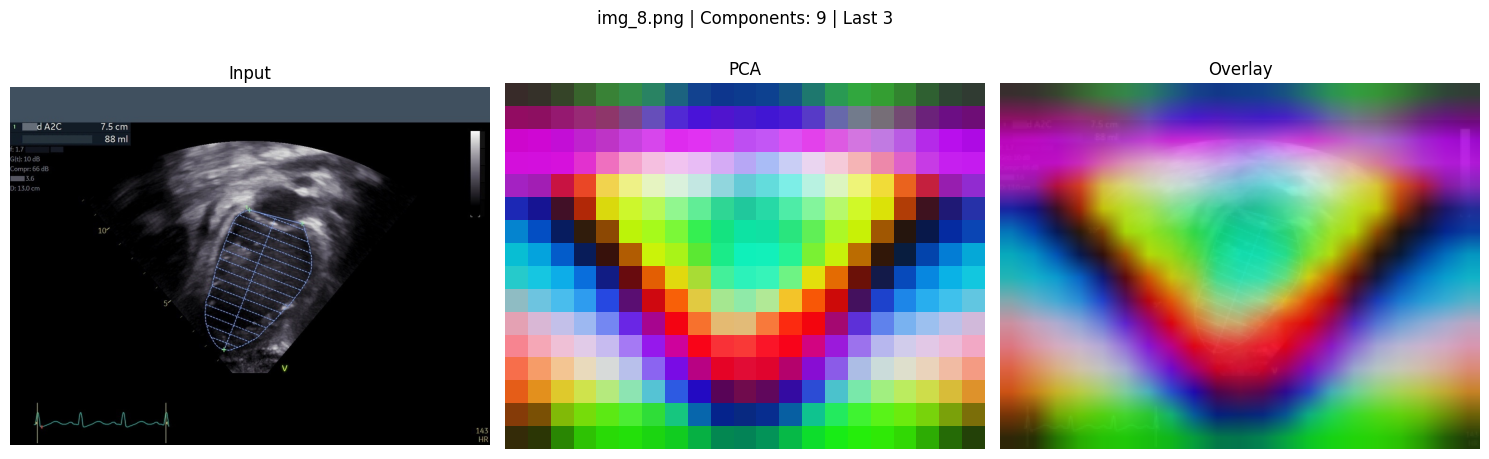

In [49]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for image_path in image_paths:
    with Image.open(image_path) as source_image:
        image = source_image.convert('RGB')
    resized_image = resize_transform(image, IMAGE_SIZE, patch_size)
    normalized_image = TF.normalize(
        resized_image, mean=IMAGENET_MEAN, std=IMAGENET_STD,
    )
    features = extract_features(model, normalized_image, device)

    for n_components in PCA_COMPONENTS:
        pca_rgb = project_pca(
            features, n_components, PCA_WHITEN,
            PCA_COLOR_SCALE, PCA_RANDOM_STATE,
        )
        output_path = OUTPUT_DIR / f'{image_path.stem}_pca_{n_components}.png'
        show_pca(
            image, resized_image, pca_rgb, image_path.name, n_components, output_path,
        )